---
<p style="text-align: center;font-size: 2em;font-weight: bold;">
Projet numérique de Probabilités 2025/26
</p>

---


# Introduction

On va s'intéresser à la simulation de champs aléatoires gaussiens. On peut définir un champ aléatoire Gaussien comme une collection de variables aléatoires indexées par un ensemble telles que toute combinaison linéaire finie de ces variables aléatoires suit une loi normale. Pour simplifier, nous nous intéresserons à des champs aléatoires gaussiens définis sur une grille régulière de points dans un domaine  $\mathbb{R}^2$. 

Un champ aléatoire Gaussien est entièrement caractérisé par son espérance et sa fonction de covariance. L'espérance est une fonction qui attribue à chaque point du domaine la valeur moyenne de la variable aléatoire associée à ce point. La fonction de covariance est une fonction qui décrit comment les variables aléatoires associées à deux points différents du domaine sont corrélées entre elles. 

Un exemple classique de fonction de covariance est la fonction exponentielle quadratique (ou gaussienne) définie par :
$$C(x, y) = \sigma^2 \exp\left(-\frac{\|x - y\|^2}{a}\right)$$
où  $\sigma^2$ est la variance,  $a$ est le facteur d'échelle, et $\|x - y\|$ est la distance euclidienne entre les points  $x$ et $y$.
Une telle fonction de covariance implique que les points proches dans le domaine ont des valeurs de champ aléatoire fortement corrélées, tandis que les points éloignés ont des valeurs faiblement corrélées. Elle est souvent utilisée pour modéliser des phénomènes naturels où la corrélation diminue avec la distance. 

Dans ce projet, nous allons implémenter une méthode pour simuler des champs aléatoires gaussiens sur une grille régulière de points dans un domaine  $\mathbb{R}^2$. Nous utiliserons dans un premier temps la méthode de la décomposition de Cholesky pour générer des échantillons de champs aléatoires gaussiens à partir de leur fonction de covariance. Dans un second temps, nous explorerons un méthode plus efficace basée sur la représentation spectrale de la fonction de covariance. Enfin, nous verrons comment conditionner ces simulations sur des observations ponctuelles.

# Simulation par la méthode de Cholesky

Quitte à réarranger les points de la grille, on peut supposer que l'on a une liste finie de points  $x_1, x_2, \ldots, x_n$ dans  $\mathbb{R}^2$ où l'on souhaite simuler le champ aléatoire Gaussien. La fonction de covariance  $C$ permet de construire la matrice de covariance  $K$ définie par :

$$K_{ij} = C(x_i, x_j)$$

On va implementer la méthode de Cholesky pour générer des réalisations de champs aléatoires gaussiens à partir de cette matrice de covariance.

1. Ecrire une fonction "covariance_gaussienne" qui prend en entrée une matrice de distances, ainsi que les paramètres  $\sigma^2$ et  $a$, et qui retourne la valeur de la fonction de covariance gaussienne entre ces deux points.

In [16]:
import numpy as np
from scipy.spatial import distance_matrix
import matplotlib.pyplot as plt

np.random.seed(12345)

def covariance_gaussienne(mat, variance, a, i, j):
    return variance * np.exp(- (mat[i, j] * mat[i, j]) / a)

2. Discrétiser le domaine  $[0, 1] \times [0, 1]$ en une grille régulière de  $n \times n$ points (par exemple,  $n = 50$). Construire la matrice de distances entre tous les points de la grille.

Pour tout $a \in \mathbb{Z}$ et $b \in \mathbb{N}^{*}$, on note respectivement $q(a,b)$ et $\text{a mod b}$ le quotient et le reste de la division euclidienne de $a$ par $b$.

On choisit la convention d'ordonner les $n^2$ points dans l'ordre suivant : 
$$\bigl( 0, 0\bigr) , \bigl( 0, \frac{1}{n - 1} \bigr), \bigl( 0, \frac{2}{n - 1} \bigr) , ... , \bigl(0, 1 \bigr) , \bigl( \frac{1}{n - 1}, 0 \bigr) , \bigl( \frac{1}{n - 1}, \frac{1}{n - 1} \bigr) , \bigl( \frac{1}{n - 1}, 1 \bigr) , ..., \bigl( 1, 1 \bigr) $$


Ainsi, dans la matrice produite ci-dessous, si $i \in \llbracket 0, n^2 - 1 \rrbracket$, et $j \in \llbracket 0, n^2 - 1 \rrbracket$, alors `mat_dist[i, j]` correspond à **la distance entre $(\frac{q(i, n)}{n - 1}, \frac{\text{i mod n}}{n - 1})$, et $(\frac{q(j, n)}{n - 1}, \frac{\text{j mod n}}{n - 1})$.**

In [11]:
n = 50
m = n * n
mat_dist = np.zeros((m,m))
I, J = np.indices((m,m))
mat_dist = np.sqrt( (((I // n) - (J // n)) / (n  - 1)) * (((I // n) - (J // n)) / (n  - 1)) + (((I % n) - (J % n)) / (n  - 1)) * (((I % n) - (J % n)) / (n - 1)))

3. Utiliser la fonction "covariance_gaussienne" pour construire la matrice de covariance $K$ en évaluant la fonction de covariance pour chaque paire de points dans la grille puis calculer la décomposition de Cholesky de $K$ (voir *np.linalg.cholesky*).

On choisira ici  $\sigma^2 = 1$ et  $a = 0.05$.

NB : Pour assurer la stabilité numérique, on peut ajouter un petit terme de régularisation à la diagonale de la matrice de covariance avant de calculer la décomposition de Cholesky (par exemple,  $10^{-10} I$ où  $I$ est la matrice identité).

In [12]:
sigma2 = 1.0
a = 0.05
K = (np.vectorize(covariance_gaussienne, excluded=[0, 1, 2], otypes=[float]))(mat_dist, sigma2,a,I, J)
K = K + np.power(10., -10) * np.identity(m)
L = np.linalg.cholesky(K)

*Remarque* : On nous demande d'utiliser la fonction `covariance_gaussienne` écrite précédement. Le code ci-dessous, n'utilisant pas cette fonction, est plus rapide !

In [13]:
sigma2 = 1.0
a = 0.05
K = sigma2 * np.exp(- np.power(mat_dist, 2) / a)
K = K + np.power(10., -10) * np.identity(m)
L = np.linalg.cholesky(K)

4. Générer et représenter une réalisation du champ aléatoire Gaussien centré et de covariance $K$.

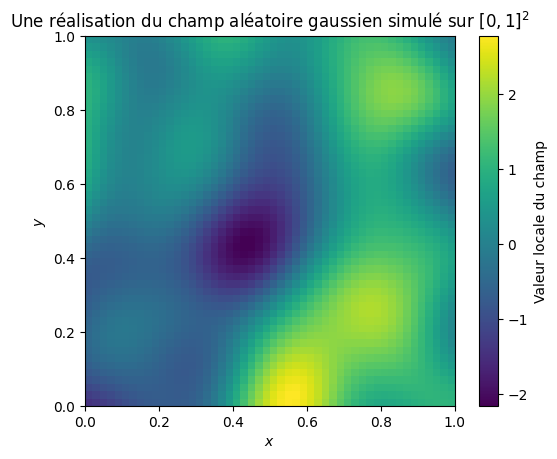

In [14]:
rng = np.random.default_rng(12345)
Y = rng.standard_normal(m)
Z = 0 + np.dot(L, Y)
plt.imshow(Z.reshape(n,n).transpose(), origin="lower", extent = [0, 1, 0, 1])
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.colorbar(label = "Valeur locale du champ")
plt.title("Une réalisation du champ aléatoire gaussien simulé sur $[0, 1]^2$")
plt.show()

On remarque en tout cas que la représentation graphique du résultat est cohérente : les points proches sont fortements corrélés, tandis que les points plus éloignés les uns des autres le sont beaucoup moins !

5. Essayer d'augmenter le nombre de pas de discrétisation. Que remarquez-vous ? Expliquer pourquoi.

On remarque que le calcul devient **très lent**, et **rapidement irréalisable** en temps raisonnable (dès $n = 220$). Cela est cohérent, car les matrices créées contiennent toutes $\boxed{n^4}$ coefficients, ce qui fait rapidement **exploser le temps de calcul** !

# Simulation par la méthode spectrale 

Vu les limitations de la méthode de Cholesky pour des grilles fines, nous allons explorer une méthode alternative basée sur la représentation spectrale de la fonction de covariance. 

1. Soit $C(h) = \exp\left(-\frac{\|h\|^2}{a}\right)$, où $h \in \mathbb{R}^2$. Montrer que :
$$ C(h) = \int_{\mathbb{R}^2} \cos(\langle w, h \rangle) \frac{a}{4\pi}\exp\left(-\frac{a\|w\|^2}{4}\right) dw $$

NB: on pourra s'inspirer du calcul de la fonction caractéristique d’un vecteur gaussien en annexe du chapitre IV du cours.

On pose 

$$I =\int_{\mathbb{R}^2} \cos(\langle w, h \rangle) \frac{a}{4\pi}\exp\left(-\frac{a\|w\|^2}{4}\right) dw$$

Soit $h \in \mathbb{R}^2$. 

On note également $b = (e_1, e_2)$ la base canonique de $\mathbb{R}^2$. On note $h = h_1 e_1 + h_2 e_2$ l'écriture de $h$ dans cette base.

Par **Fubini** :
$$
\frac{4\pi}{a} I =
\int_{\mathbb{R}}
\int_{\mathbb{R}}
\cos(\omega_1 h_1)\,
\cos(\omega_2 h_2)\,
\exp\left(-\frac{a\,\omega_1^2}{4}\right)\,
\exp\left(-\frac{a\,\omega_2^2}{4}\right)
\, d\omega_1 \, d\omega_2

- 

\int_{\mathbb{R}}
\int_{\mathbb{R}}
\sin(\omega_1 h_1)\,
\sin(\omega_2 h_2)\,
\exp\left(-\frac{a\,\omega_1^2}{4}\right)\,
\exp\left(-\frac{a\,\omega_2^2}{4}\right)
\, d\omega_1 \, d\omega_2
$$

D'où : 
$$
\boxed{\frac{4\pi}{a} I = U_1 U_2 - V_1 V_2}
$$

où :
$$
\boxed{\forall i \in \{1,2\}, \quad
U_i
=
\int_{\mathbb{R}}
\cos(\omega_i h_i)\,
\exp\!\left(-\frac{a\,\omega_i^2}{4}\right)
\, d\omega_i}
$$

$$
\boxed{\forall i \in \{1,2\}, \quad
V_i
=
\int_{\mathbb{R}}
\sin(\omega_i h_i)\,
\exp\!\left(-\frac{a\,\omega_i^2}{4}\right)
\, d\omega_i}
$$

Soit $i \in \{1,2\}$. Puisque $t \mapsto \sin(t h_i)\,\exp\!\left(-\frac{a\,t^2}{4}\right)$ est intégrable et impaire, $\boxed{V_i = 0}$.

On définit :
$$
g:\ \begin{array}{ccc}
\mathbb{R} &\longrightarrow& \mathbb{R} \\
u &\longmapsto& \displaystyle \int_{\mathbb{R}} \cos(u x)\exp\!\left(-\frac{a x^2}{4}\right)\,dx
\end{array}
$$

et
$$
\phi:\ \begin{array}{ccc}
\mathbb{R}^2 &\longrightarrow& \mathbb{R} \\
(u,x) &\longmapsto& \cos(u x)\,
\exp\!\left(-\frac{a x^2}{4}\right)
\end{array}
$$

Ainsi,

$$
\forall u \in \mathbb{R}, \quad
g(u) = \int_{\mathbb{R}} \phi(u,x)\,dx
$$

Puisque :
- Pour tout $u \in \mathbb{R}$, $x \mapsto \phi(u,x)$ est <u>continue</u> et <u>intégrable</u> sur $\mathbb{R}$
- Pour tout $x \in \mathbb{R}$, $u \mapsto \phi(u,x)$ est <u>de classe $C^1$</u> sur $\mathbb{R}$
- Pour tout $u \in \mathbb{R}$, $x \longmapsto \frac{\partial \phi}{\partial u}(u,x)$ est bien <u>définie</u> et <u>continue</u>. En effet, si $u \in \mathbb{R}$, on a :

$$
\forall x\in\mathbb{R},\ 
\frac{\partial \phi_i}{\partial u}(u,x)
= -x\sin(u x)\exp\!\left(-\frac{a x^2}{4}\right)
$$

- Pour tout $(u, x) \in \mathbb{R}^2$, on a $\left| \frac{\partial \phi}{\partial u}(u,x) \right| \leq \Phi(x)$

où la fonction $\Phi$ est définie par :
$$
\Phi:\ \begin{array}{ccc}
\mathbb{R} &\longrightarrow& \mathbb{R} \\
x &\longmapsto& \left|x\right|\,
\exp\!\left(-\frac{a x^2}{4}\right)
\end{array}
$$

Comme la fonction $\Phi$ est intégrable, on peut appliquer le <u>théorème de dérivation de Leibniz</u>. Celui-ci nous assure que $g$ est de classe $C_1$ et que :

$$
\boxed{\forall u \in \mathbb{R}, \quad
g'(u)
=
- \int_{\mathbb{R}}
x\, \sin(u x)\,
\exp\!\left(-\frac{a x^2}{4}\right)\,dx}
$$

Soit $u \in \mathbb{R}$. Par <u>intégration par partie</u> :

$$
g'(u)
=
\frac{2}{a} \left( \underbrace{
\left[
\sin(u x)\,
\exp\!\left(-\frac{a x^2}{4}\right)
\right]_{-\infty}^{+\infty}
}_{=\,0} - \int_{\mathbb{R}}
u\,\cos(u x)\,
\exp\!\left(-\frac{a x^2}{4}\right)\,dx
\right) = - \frac{2\, u}{a}g(u)
$$

La <u>résolution de cette équation différentielle</u> nous donne qu'il existe $\lambda \in \mathbb{R}$ tel que :
$$
\boxed{\forall u \in \mathbb{R}, \quad
g(u) = \lambda\,\exp\!\left(-\frac{u^2}{a}\right)}
$$

Or $g(0) = \sqrt{\frac{4 \, \pi}{a}}$ donc $\lambda = \sqrt{\frac{4 \, \pi}{a}}$.

De plus :

$$
\forall i\in\{0,1\},\ U_i = g(h_i)
$$

Donc :
$$
\frac{4\, \pi}{a} I = \frac{4 \, \pi}{a} \, \exp\!\left(-\frac{h_1^2}{a}\right) \, \exp\!\left(-\frac{h_2^2}{a}\right)
$$

et finalement :
$$
\boxed{\int_{\mathbb{R}^2} \cos(\langle w, h \rangle) \frac{a}{4\pi}\exp\left(-\frac{a\|w\|^2}{4}\right) dw
=
I
= 
\exp\!\left(-\frac{h_1^2}{a}\right) \, \exp\!\left(-\frac{h_2^2}{a}\right)
=
\exp\!\left(-\frac{\|h\|^2}{a}\right)
=
C(h)}
$$



2. Soient $W$ et $\Phi$ deux variables aléatoires indépendantes, de lois respectives $\mathcal{N}(0, \frac{2}{a} I_2)$, avec $I_2$ la matrice identité de dimension 2, et $\mathcal{U}[0, 2\pi[$. Montrer que la variable aléatoire définie en tout point $x \in \mathbb{R}^2$ par :
$$ Z(x) = \sqrt{2} \cos(\langle W, x \rangle + \Phi) $$
est d'espérance nulle et de fonction de covariance $C$.

Soit $x \in \mathbb{R}^2$. 

On cherche à déterminer $\mathbb{E} \left( Z(x) \right)$. Commençons par déterminer $\mathbb{E} \left( Z(x) \,| \,  W \right)$.

Soit $w \in \mathbb{R}$. Alors
$$
\mathbb{E} \left( Z(x) \,| \,  W = w\right) = \sqrt{2} \, \mathbb{E} \left( \cos(\langle W, x \rangle + \Phi) \, | \, W = w\right) = \mathbb{E} \left( \cos(\alpha + \Phi) \right)
$$
où $\alpha \coloneqq \langle w, x \rangle$, car $\Phi$ et $W$ sont <u>indépendantes</u>. Donc :
$$
\mathbb{E} \left( Z(x) \,| \,  W = w\right) 
= 
\sqrt{2} \,
\int_{0}^{2\pi}
\frac{1}{2\pi}\,
\cos(\alpha + \phi)\,d\phi
=
0
$$

Donc :

$$
\boxed{\mathbb{E} \left( Z(x) \,| \,  W \right) = \tilde{0}}
$$
où $\tilde{0}$ désigne la variable aléatoire nulle sur tout l'univers.


Donc :
$$
\boxed{\mathbb{E} \left( Z(x)\right) = \mathbb{E} \left( \mathbb{E} \left( Z(x) \,| \,  W \right) \right) = \mathbb{E} \left( \tilde{0} \right) = 0}
$$

Montrons que $C$ est la fonction de covariance. Soit $y \in \mathbb{R}^2$.

Alors :
$$
\mathrm{Cov} \left( Z(x), Z(y) \right) = \mathbb{E} \left( \left(Z(x) - \mathbb{E} \left( Z(x) \right) \right) \left( Z(y) - \mathbb{E} \left( Z(y) \right) \right) \right) = \mathbb{E} \left(Z(x) \, Z(y) \right)
$$

Donc :

$$
\mathrm{Cov} \left( Z(x), Z(y) \right) = 2 \, \mathbb{E} \left(\cos(\underbrace{\langle W, x \rangle}_{=: U} + \Phi) \, \cos(\underbrace{\langle W, y \rangle}_{=: V} + \Phi) \right)
$$

Donc :

$$
\boxed{\mathrm{Cov} \left( Z(x), Z(y) \right) = \mathbb{E} \left( \cos(U - V) \right) + \mathbb{E} \left( \cos(U + V + 2 \, \Phi) \right)}
$$

La même méthode que que celle utilisée pour prouver la nullité de l'espérance de $Z(x)$ permet de prouver que $\boxed{\mathbb{E} \left( \cos(U + V + 2 \, \Phi) \right) = 0} $.

Donc :

$$
\boxed{\mathrm{Cov} \left( Z(x), Z(y) \right) = \mathbb{E} \left( \cos(\langle W, x - y \rangle) \right) = \mathrm{Re} \left( \mathbb{E}\left( e^{i \, \langle W, x - y \rangle} \right) \right) = \mathrm{Re} \left( \Phi_W(x - y) \right) = \mathrm{Re} \left( e^{i \, \langle \underbrace{\mathbb{E} \left( W \right)}_{= 0}, x - y \rangle - \frac{1}{a} \; \langle x - y, I_2 \, (x - y) \rangle} \right) = e^{- \frac{\| x - y \|^2}{a}} = C(x - y)}
$$

Ainsi, $C$ est bien la fonction de covariance.

3. Soient les suites de variables aléatoires indépendantes $(W_n)_{n \in \mathbb{N}}$ et $(\Phi_n)_{n \in \mathbb{N}}$ telles que $W_n \sim \mathcal{N}(0, \frac{2}{a} I_2)$ et $\Phi_n \sim \mathcal{U}([0, 2\pi])$. Montrer que pour tout ensemble fini de points  $x_1, \ldots, x_n$ dans  $\mathbb{R}^2$ , le vecteur aléatoire $Y = (Y(x_1), \ldots, Y(x_n))$ où :
$$ Y(x_i) = \sqrt{\frac{2}{N}} \sum_{k=1}^{N} \cos(\langle W_k, x_i \rangle + \Phi_k) $$
tend vers un vecteur aléatoire de loi normale multivariée d'espérance nulle et de matrice de covariance $K$ définie par  $K_{ij} = C(x_i - x_j)$.

Pour plus de clarté, nous utiliserons les notations suivantes :  $Y_N = (Y_N(x_1), \ldots, Y_N(x_n))$ où :
$$ Y_N(x_i) = \sqrt{\frac{1}{N}} \sum_{k=1}^{N} \underbrace{ \sqrt{2} \, \cos(\langle W_k, x_i \rangle + \Phi_k)}_{=: V_k^{i}}$$

On pose :
$$\forall k \in \mathbb{N}, V_k = \left( V_k^{1}, \ldots, V_k^{n} \right)$$

Alors :
$$Y_N = \frac{1}{\sqrt{N}} \, \sum_{k=1}^{N} V_k$$

Naturellement, les $V_k$ sont <u>i.i.d</u>. Par ailleurs,
$$\boxed{\forall k \in \mathbb{N}, \mathbb{E} \left( V_k \right) = \left(\underbrace{\mathbb{E} \left( V_k^{1} \right)}_{= 0 \text{ d'après Q.2}}, \ldots, \underbrace{\mathbb{E} \left( V_k^{n} \right)}_{= 0} \right) = (0, \ldots, 0)}
$$

D'autre part, si $k \in \mathbb{N}$, $u,v \in \llbracket 1, n \rrbracket$, alors :

$$
\mathrm{Cov} \left( V_k^{u}, V_k^{v} \right) = C(x_u- x_v)
$$ 
d'après la question précédente.

Donc si on définit la matrice $K$ par $K_{ij} = C(x_i - x_j)$, alors <u>le théorème central limite multi-dimensionnel</u> nous donne que 
$$
\boxed{\frac{\sum_{k=1}^{N} V_k - N. (0, \ldots, 0)}{\sqrt{N}} \xrightarrow{\mathcal{L}} \Upsilon \sim \mathcal{N} \left(0, K \right)}
$$
c'est-à-dire :
$$
\boxed{Y_N\xrightarrow{\mathcal{L}} \Upsilon \sim \mathcal{N} \left(0, K \right)}
$$

4. Implémenter une fonction basée sur cette méthode pour simuler un champ aléatoire gaussien sur une grille régulière de points dans le domaine  $[0, 1] \times [0, 1]$. Cette fonction prendra en entrée les coordonnées des points de la grille, $a$ et  $N$ et retournera une réalisation du champ aléatoire gaussien simulé.

*Remarque* : Le champ aléatoire gaussien simulé est centré.

In [34]:
def champ_spectre(coord, a, N) :
    m = len(coord)
    n = int(np.sqrt(m))
    W = rng.multivariate_normal([0, 0], (2/a)*np.identity(2), N)
    Phi = rng.uniform(0, 2*np.pi, N)
    termes = np.cos(np.dot(coord, W.transpose()) + Phi)
    Y = np.sqrt(2/N) * np.sum(termes, axis=1)
    return Y.reshape(n,n)

5. Tester cette fonction pour différentes valeurs du nombre de points de discrétisation et de $N$. Proposer un diagnostic permettant de calibrer $N$ afin que les résultats soient conformes aux attentes. Comparer les résultats obtenus avec ceux de la méthode de Cholesky. Quels sont les avantages et les inconvénients de chaque méthode ?

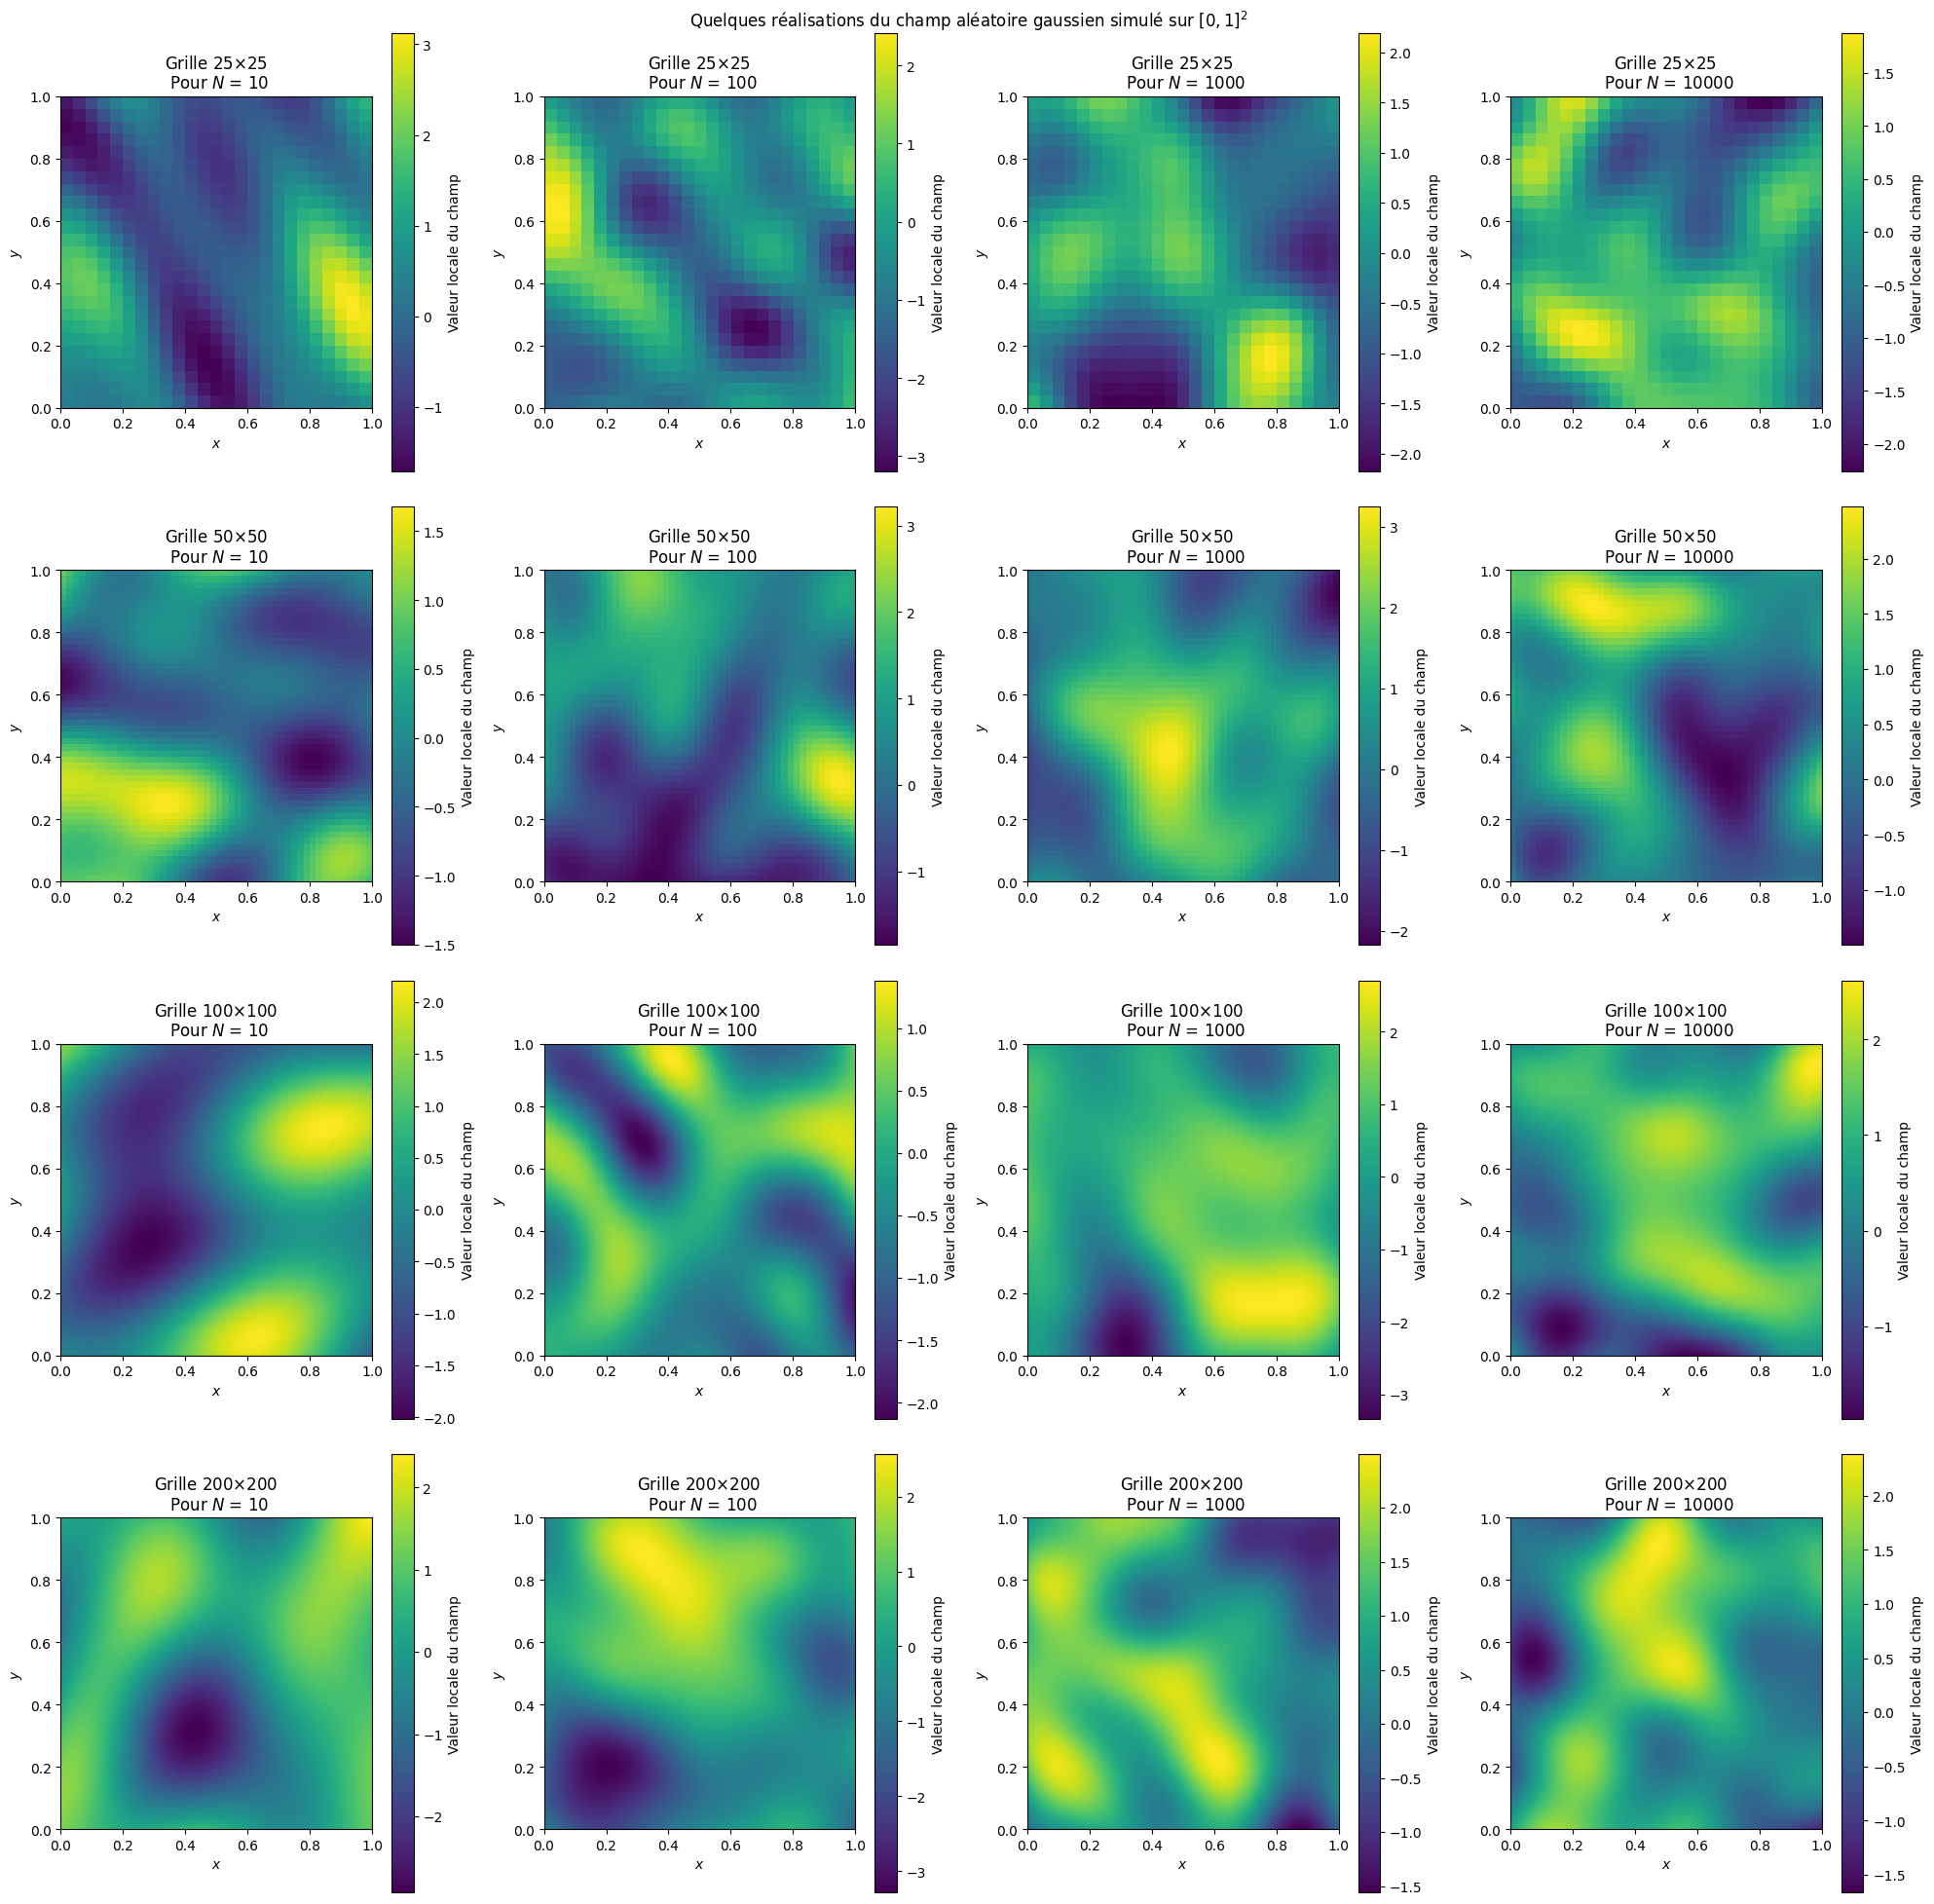

In [36]:
sigma2 = 1.0
a = 0.05

def coord(n) :
    coord_int = np.linspace(0, 1, n)
    coords = np.array([[x, y] for x in coord_int for y in coord_int])
    return coords

n = [25, 50, 100, 200]
N = [10, 100, 1000, 10000]
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(20, 20))
for i in range(4) :
    coord_aux = coord(n[i])
    for j in range(4) :
        im = axes[i,j].imshow(champ_spectre(coord_aux, a, N[j]).transpose(), origin="lower", extent=[0, 1, 0, 1])
        axes[i,j].set_xlabel("$x$")
        axes[i,j].set_ylabel("$y$")
        axes[i,j].set_title(f"Grille ${n[i]} × {n[i]}$ \n Pour $N$ = {N[j]}")
        plt.colorbar(im, ax=axes[i,j], label="Valeur locale du champ")
fig.suptitle("Quelques réalisations du champ aléatoire gaussien simulé sur $[0, 1]^2$")
plt.tight_layout()
plt.show()

Il s'agit de chercher à calibrer $N$ afin que les résultats soient conformes aux attentes. Pour cela, il est envisageable d'employer la méthode suivante :
- Fixer $N \in \mathbb{N}$. 
- Estimer une matrice de covariance empirique : $K^{\text{exp}}(N) = \left( \mathrm{Cov} \left(Y_N(x_i), Y_N(x_j) \right)^{\text{exp}} \right)_{(i,j) \in \llbracket 0, n^2\rrbracket }$
- Calculer la grandeur suivante :
$$
S_N = \frac{1}{n^2} \, \sqrt{\sum_{i=1}^{n^2} \sum_{j=1}^{n^2} \left(K_{i,j}^{\text{exp}}(N) - C \left(x_i - x_j \right) \right)^2}
$$
- Évaluer l'évolution de $S_N$ en fonction de $N$. Quand les variations de $S_N$ deviennent faible, on tendra à considérer moins intéressante l'augmentation de la valeur de $N$.

Mettons en place cette méthode.

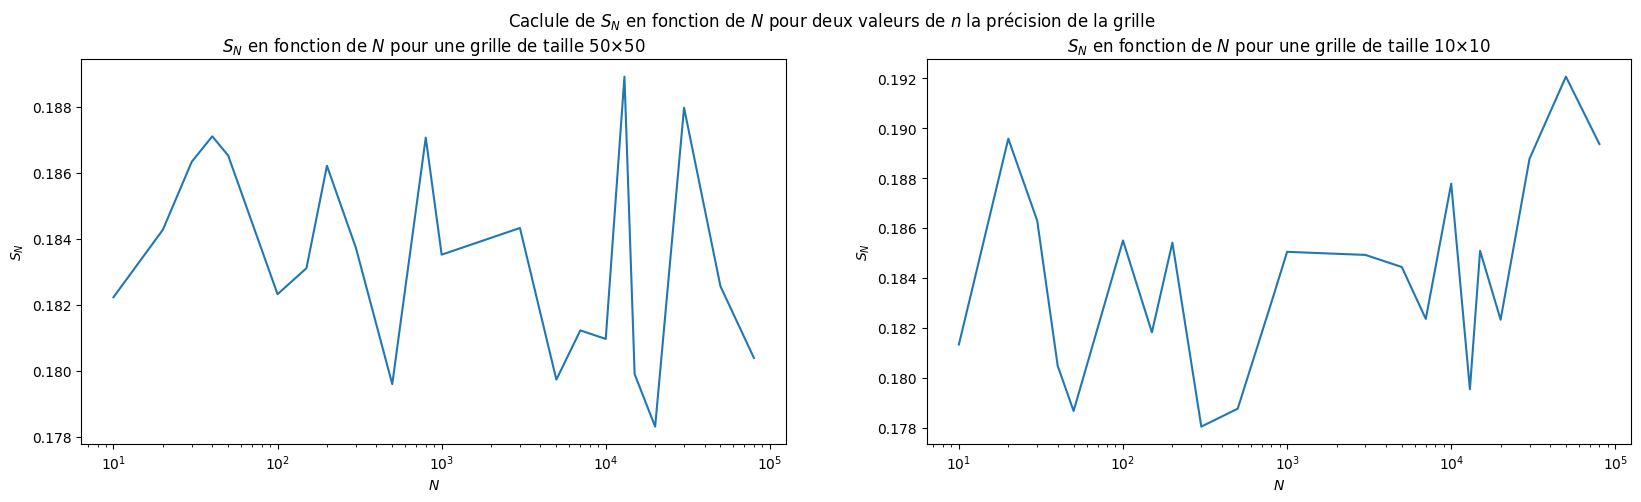

In [ ]:
m = 30

def multiples_resultats(n, a, N, m):
    coord_aux = coord(n)
    ans = np.stack([champ_spectre(coord_aux, a, N) for i in range(m)], axis=0)
    return ans

def S_N(n, a, N, m):
    I, J = np.indices((n*n,n*n))
    mat_dist_2 =  (((I // n) - (J // n)) / (n  - 1)) * (((I // n) - (J // n)) / (n  - 1)) + (((I % n) - (J % n)) / (n  - 1)) * (((I % n) - (J % n)) / (n - 1))
    mat_res = multiples_resultats(n, a, N, m)
    mat_res = mat_res - mat_res.mean(axis=0, keepdims=True)
    mat_res = mat_res.reshape((m,n * n))
    mat_cov = (1 / m) * mat_res.T @ mat_res
    mat_cov_theo = np.exp(- mat_dist_2 / a)
    return np.sqrt(np.sum((mat_cov - mat_cov_theo)*(mat_cov - mat_cov_theo))) * (1 / (n**2))

N = [10, 20, 30, 40, 50, 100, 150, 200, 300 , 500, 800, 1000, 3000, 5000, 7000, 10000, 13000, 15000, 20000, 30000, 50000, 80000]
n = [50, 10]
y_1 = np.array([[S_N(n[0], a, N[i], m) for i in range(len(N))] for j in range(20)]).mean(axis=0)
y_2 = np.array([[S_N(n[1], a, N[i], m) for i in range(len(N))] for j in range(20)]).mean(axis=0)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20,5))
axes[0].semilogx(N, y_1, label=f"Pour une grille ${n[0]}\times{n[0]}$")
axes[1].semilogx(N, y_2, label=f"Pour une grille ${n[1]}\times{n[1]}$")
axes[0].set_xlabel("$N$")
axes[0].set_ylabel("$S_N$")
axes[0].set_title(f"$S_N$ en fonction de $N$ pour une grille de taille ${n[0]} × {n[0]}$")
axes[1].set_xlabel("$N$")
axes[1].set_ylabel("$S_N$")
axes[1].set_title(f"$S_N$ en fonction de $N$ pour une grille de taille ${n[1]} × {n[1]}$")
fig.suptitle(f"Calcul de $S_N$ en fonction de $N$ pour deux valeurs de $n$ (précision de la grille)")
plt.show()

On s'attendait à une courbe décroissante en fonction de $N$. Ce n'est pourtant pas le cas, et cela est dû à un bruitage lié au choix de N. Nous allons donc envisager une autre stratégie. Elle est la suivante :
- Fixer $N$
- Estimer empiriquement le vecteur $U$ défini par $U = \left( \left(Y_{2N}(x_i) - Y_{N}(x_i) \right)^2 \right)_{1 \leq i \leq n^2}$
- Cacluler la grandeur suivante :
$$S_N^{\text{bis}} = \frac{1}{n} \, \sqrt{ \sum_{i = i}^{n^2} U_i}$$
- Evaluer l'évolution de $S_N^{\text{bis}}$ en fonctiond de $N$. Quand les variations de $S_N^{\text{bis}}$ deviennent faible, on tendra à considérer moins intéressante l'augmentation de la valeur de $N$.

Mettons en oeuvre cette méthode en vue de meilleurs résultats que précédemment.

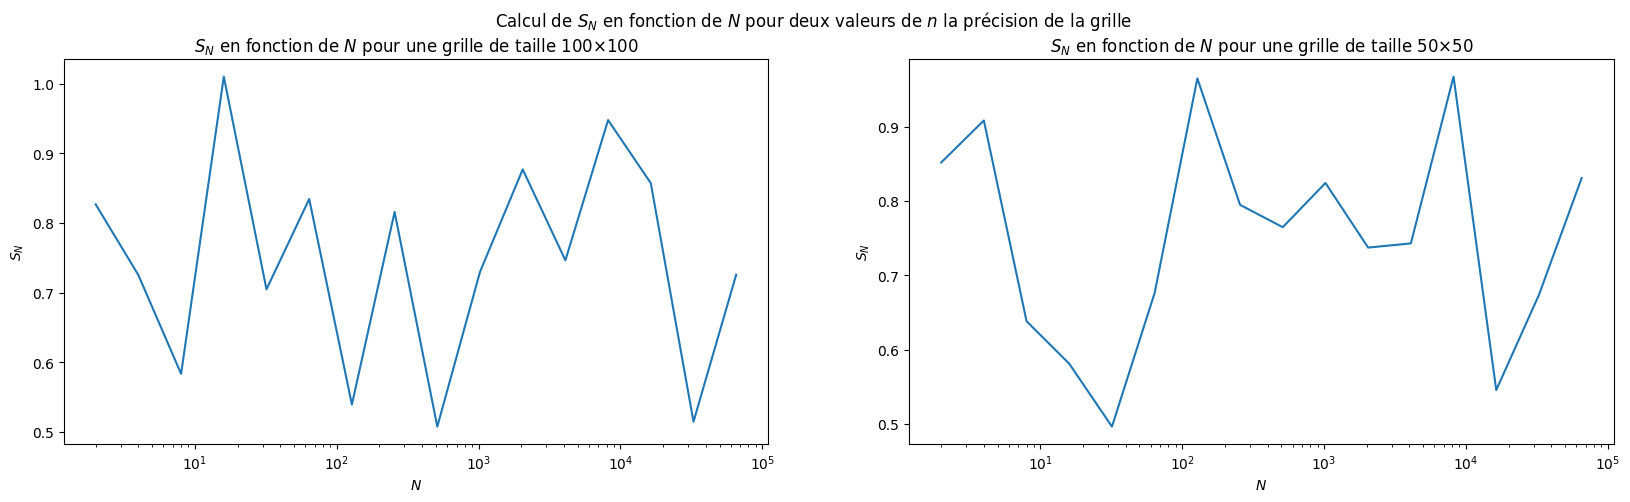

In [23]:
N_size = 17
N = [2**i for i in range(1, N_size + 1)]

def modified_champ_spectre(coord, a, Ns):
    m = int(np.sqrt(len(coord)))
    Ns = np.sort(Ns)
    N_length = len(Ns)
    N_max = Ns[N_length - 1]
    W = rng.multivariate_normal([0, 0], (2/a) * np.identity(2), N_max)
    Phi = rng.uniform(0, 2 * np.pi, N_max)
    termes = np.cos(np.dot(coord, W.transpose()) + Phi)
    ans = []
    for i in range(N_length):
        ans.append((np.sqrt(2/Ns[i]) * np.sum(termes[:, :Ns[i]], axis=1)).reshape(m,m).transpose())
    return ans

n = [100, 50]
mats_res_1 = modified_champ_spectre(coord(n[0]), a, N)
mats_res_2 = modified_champ_spectre(coord(n[1]), a, N)

U_1 = np.zeros((N_size - 1, n[0], n[0]))
U_2 = np.zeros((N_size - 1, n[1], n[1]))
for i in range(N_size - 1):
    U_1[i, :, :] = (mats_res_1[i + 1] - mats_res_1[i]) * (mats_res_1[i + 1] - mats_res_1[i])
    U_2[i, :, :] = (mats_res_2[i + 1] - mats_res_2[i]) * (mats_res_2[i + 1] - mats_res_2[i])

S_N_bis_1 = [1/ (n[0]) * np.sqrt(np.sum(U_1[i, :, :])) for i in range(N_size - 1)]
S_N_bis_2 = [1/ (n[1]) *np.sqrt(np.sum(U_2[i, :, :])) for i in range(N_size - 1)]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20,5))
axes[0].semilogx(N[: N_size - 1], S_N_bis_1, label=f"Pour une grille ${n[0]}\times{n[0]}$")
axes[1].semilogx(N[: N_size - 1], S_N_bis_2, label=f"Pour une grille ${n[1]}\times{n[1]}$")
axes[0].set_xlabel(f"$N$")
axes[0].set_ylabel(f"$S_N$")
axes[0].set_title(f"$S_N$ en fonction de $N$ pour une grille de taille ${n[0]} × {n[0]}$")
axes[1].set_xlabel(f"$N$")
axes[1].set_ylabel(f"$S_N$")
axes[1].set_title(f"$S_N$ en fonction de $N$ pour une grille de taille ${n[1]} × {n[1]}$")
fig.suptitle(f"Calcul de $S_N$ en fonction de $N$ pour deux valeurs de $n$ la précision de la grille")
plt.show()


<u>Avantages de la méthode de Cholesky :</u>
- Méthode théoriquement plus simple.
- Simple à implémenter en Python grâce à la bibliothèque `numpy`.
- La précision de la méthode ne dépend pas du choix d'un paramètre (comme $N$ dans la méthode spectrale).

<u>Inconvénients de la méthode de Cholesky :</u>
- Calcul de $K$ et de $L$ très lent. C'est une méthode couteuse en temps de calcul, limitant très rapidement le nombre de points de la grille.
- Perte de précision non mesurée lors de l'ajout de $10^{-10} \, I_2$ assurant le caractère symétrique défini positif de la matrice $K$ en compensant les erreurs de calcul.

<u>Avantages de la méthode spectrale : </u>
- Possibilité de simuler pour un nombre bien plus importants de points dans la grille.
- Précision adaptable de la simulation (choix de $N$).

<u>Inconvénient de la méthode spectrale :</u>
- Difficulté du choix d'une valeur de $N$ optimale pour limiter le temps de calcul sans trop perdre en précision.

# Simulation conditionnelle 

On suppose désormais que l'on dispose de valeurs observées du champ aléatoire Gaussien en certains points du domaine. On souhaite simuler des réalisations conditionnelles du champ aléatoire Gaussien en tenant compte de ces observations. On travaillera désormais avec une grille de taille $100 \times 100$.
Soit $X$ un vecteur aléatoire Gaussien partitionné en deux sous-vecteurs $X_1$ et $X_2$, où $X_1$ représente les points observés et $X_2$ les points non observés. 

1. Rappeler l'expression de la distribution jointe de $X = (X_1, X_2)$ puis de la distribution conditionnelle de $X_2$ sachant $X_1$. Montrer que la différence entre l'espérance conditionnelle et le vecteur des points non observés est un vecteur Gaussien d'espérance nulle indépendant du vecteur des points non observés.

*Remarque* : Pour $\ell \in \mathbb{N}^*$, on identifiera les éléments de $\mathbb{R}^{\ell}$ aux vecteurs **lignes** à $\ell$ réels.

Notons :
$$\forall i,j \in \{1,2\}, i \neq j, \; m_i \coloneqq \mathbb{E} (X_i), \; C_i \coloneqq \mathrm{Cov}(X_i,X_i), \; C_{i,j} \coloneqq \mathrm{Cov}(X_i,X_j), \: \ell_i \coloneqq \mathrm{len}(X_i)$$
$$m \coloneqq (m_1 \quad m_2) = \mathbb{E} (X), \; C \coloneqq \begin{pmatrix}
C_1 & C_{1,2} \\
C_{2,1} & C_2
\end{pmatrix} = \mathrm{Cov}(X,X) \quad \text{(écriture par blocs)}$$
$$\forall x_1 \in \mathbb{R}^{\ell_1}, \: m_{x_1} \coloneqq m_2 + C_{2,1} C_{1}^{-1}(x_1 - m_1), \: C\!S_2 \coloneqq C_2 - C_{2,1} C_{1}^{-1} C_{1,2}$$

avec notamment $C, C_1$ et $C\!S_2$ sont inversibles.

$X \sim \mathcal{N}(m, C)$, c'est-à-dire que sa densité de probabilité est 
$$\boxed{f_X:\ \begin{array}{ccc}
\mathbb{R}^{10^4} &\longrightarrow& \mathbb{R}_+ \\
x &\longmapsto& \frac{1}{(2 \pi)^{5 \cdot 10^3} \sqrt{\mathrm{det}(C)}} \exp\!\left(-\frac{1}{2}(x-m) C^{-1} (x-m)^T\right)
\end{array}}$$

$\forall x_1 \in \mathbb{R}^{\ell_1}, \: \left(X_2 \, | \,  X_1 = x_1\right) \sim \mathcal{N}(m_{x_1}, C\!S_2)$, c'est-à-dire que sa densité de probabilité est 
$$\boxed{f_{\left(X_2 \, | \,  X_1 = x_1\right)}:\ \begin{array}{ccc}
\mathbb{R}^{\ell_2} &\longrightarrow& \mathbb{R}_+ \\
x_2 &\longmapsto& \frac{1}{(2 \pi)^\frac{^{\ell_2}}{2} \sqrt{\mathrm{det}(C\!S_2)}} \exp\!\left(-\frac{1}{2}(x_2-m_{x_1}) C\!S_2^{-1} (x_2-m_{x_1})^T\right)
\end{array}}$$

Posons $\varepsilon = \mathbb{E}(X_2 \,| \,  X_1) - X_2$.

On a $\mathbb{E}(X_2 \,| \,  X_1) = m_2 + C_{2,1} C_1^{-1}(X_1 - m_1)$.

Ainsi, $\varepsilon = \underbrace{C_{2,1} C_1^{-1} X_1 - X_2}_{\coloneqq \Sigma} + \underbrace{m_2 - C_{2,1} C_1^{-1} m_1}_{\coloneqq \Gamma}$.

Or, toute combinaison linéaire finie de composantes de $\Sigma$ est une combinaison linéaire finie de composantes de $X$, donc suit une loi normale car $X$ est un vecteur aléatoire gaussien. Donc, par définition, $\Sigma$ est un vecteur aléatoire gaussien.

Or, soit $h$ une fonction mesurable telle que $\mathbb{E}(\left| h(\varepsilon) \right|) < +\infty$. Alors,
$$\mathbb{E}(h(\varepsilon)) = \int_{\mathbb{R}^{\ell_2}} h(\varsigma\, + \Gamma) \, f_{\Sigma}(\varsigma) \, d\varsigma = \int_{\mathbb{R}^{\ell_2}} h(\varsigma') \, f_{\Sigma}(\varsigma' - \Gamma) \, d\varsigma'$$
avec le changement de variable $\varsigma' = \varsigma + \Gamma$ (qui est bien valide car affine sur $\mathbb{R}^{\ell_2}$).
Ainsi,
$$\mathbb{E}(h(\varepsilon)) = \int_{\mathbb{R}^{\ell_2}} h(\varsigma') \, \frac{1}{(2 \pi)^\frac{^{\ell_2}}{2} \sqrt{\mathrm{det}(C_\Sigma)}} \exp\!\left(-\frac{1}{2}(\varsigma'-(m_{\Sigma} + \Gamma)) C_{\Sigma}^{-1} (\varsigma'-(m_{\Sigma} + \Gamma))^T\right) \, d\varsigma'$$
avec des notations génériques.

Ainsi, selon la méthode de la fonction muette, $\boxed{\varepsilon \sim \mathcal{N}(m_{\Sigma} + \Gamma, C_{\Sigma})}$. Donc $\varepsilon$ est bien un vecteur aléatoire gaussien.

Or $\mathbb{E}(\varepsilon) = \underbrace{\mathbb{E}(\mathbb{E}(X_2 \,| \,  X_1))}_{= \mathbb{E}(X_2)} - \mathbb{E}(X_2)$, d'où $\boxed{\mathbb{E}(\varepsilon) = 0}$.

Nous ne sommes pas parvenus à montrer que $\varepsilon$ était indépendant de $X_2$. Cependant, au cours de notre réflexion, il nous est apparu que $\varepsilon$ était indépendant de $X_1$. Nous en présentons donc rapidement la preuve.

$$\mathrm{Cov} (\varepsilon, X_1) = \mathrm{Cov} (\mathbb{E}(X_2 \,| \,  X_1) - X_2, X_1) = \mathrm{Cov} (C_{2,1} C_1^{-1} X_1 - X_2 + m_2 - C_{2,1} C_1^{-1} m_1, X_1) = \underbrace{C_{2,1} C_1^{-1} \mathrm{Cov}(X_1, X_1)}_{= C_{2,1} C_1^{-1} C_1 = C_{2,1}} - \underbrace{\mathrm{Cov}(X_2, X_1)}_{= C_{2,1}} + \underbrace{\mathrm{Cov}(m_2 - C_{2,1} C_1^{-1} m_1, X_1)}_{= 0}$$
d'où
$$\boxed{\mathrm{Cov} (\varepsilon, X_1) = 0}$$

Or $\Xi \coloneqq (\varepsilon \quad X_1)$ est un vecteur aléatoire gaussien, car toute combinaison linéaire finie de composantes de $\Xi$ est une combinaison linéaire finie de composantes de $X$, donc suit une loi normale car $X$ est un vecteur aléatoire gaussien. Ainsi, avec des notations usuelles :
$$\forall x \in \mathbb{R}^{10^4}, \: f_{\Xi}(x) = \frac{1}{(2 \pi)^{5 \cdot 10^3} \sqrt{\mathrm{det}(C_{\Xi})}} \exp\!\left(-\frac{1}{2}(x-m_{\Xi}) C_{\Xi}^{-1} (x-m_{\Xi})^T\right)$$
où
$$C_{\Xi} \coloneqq \begin{pmatrix}
C_{\varepsilon} & C_{\varepsilon,1} \\
C_{1,\varepsilon} & C_{1}
\end{pmatrix} = \begin{pmatrix}
C_{\varepsilon} & 0 \\
0 & C_{1}
\end{pmatrix}$$
donc
$$\forall x = (x_2 \quad x_1) \in \mathbb{R}^{10^4} = \mathbb{R}^{\ell_2} \times \mathbb{R}^{\ell_1}, \: f_{\Xi}(x) = \frac{1}{(2 \pi)^{5 \cdot 10^3} \sqrt{\mathrm{det}(C_{\varepsilon}) \, \mathrm{det}(C_{1})}} \exp\!\left(-\frac{1}{2}\underbrace{\left(x_2-m_{\varepsilon} \quad x_1-m_1\right) \begin{pmatrix}
C_{\varepsilon}^{-1} & 0 \\
0 & C_{1}^{-1}
\end{pmatrix} \begin{pmatrix}
(x_2-m_{\varepsilon})^T \\
(x_1-m_1)^T
\end{pmatrix}}_{=(x_2-m_{\varepsilon}) C_{\varepsilon}^{-1} (x_2-m_{\varepsilon})^T + (x_1-m_1) C_{1}^{-1} (x_1-m_1)^T}\right)$$
i.e.
$$\forall x = (x_2 \quad x_1) \in \mathbb{R}^{10^4} = \mathbb{R}^{\ell_2} \times \mathbb{R}^{\ell_1}, \: f_{\Xi}(x) = \frac{1}{(2 \pi)^{\frac{\ell_2}{2}} \sqrt{\mathrm{det}(C_{\varepsilon})}} \exp\!\left(-\frac{1}{2}(x_2-m_{\varepsilon}) C_{\varepsilon}^{-1} (x_2-m_{\varepsilon})^T\right) \: \frac{1}{(2 \pi)^{\frac{\ell_1}{2}} \sqrt{\mathrm{det}(C_1)}} \exp\!\left(-\frac{1}{2}(x_1-m_1) C_1^{-1} (x_1-m_1)^T\right)$$
soit
$$\forall x = (x_2 \quad x_1) \in \mathbb{R}^{10^4} = \mathbb{R}^{\ell_2} \times \mathbb{R}^{\ell_1}, \: \boxed{f_{\Xi}(x) = f_{\varepsilon}(x_2) \: f_{X_1}(x_1)}$$
En conclusion, ceci prouve que la différence entre l'espérance conditionnelle et le vecteur des points non observés est indépendante du vecteur des points observés.

On va donc chercher à simuler directement cette différence pour obtenir des réalisations conditionnelles du champ aléatoire Gaussien.

2. Générer 50 points uniformément répartis dans le domaine  $[0, 1] \times [0, 1]$ et simuler des observations du champ aléatoire Gaussien en ces points.


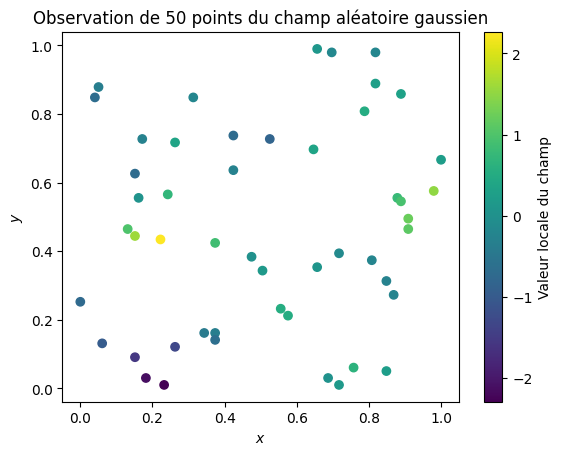

In [40]:
n = 100
coord_tot = coord(n)
pts_obs_index = rng.choice(n**2, 50, False)
pts_obs = coord_tot[pts_obs_index]
mat_dist = np.array([[np.linalg.norm(pts_obs[i] - pts_obs[j]) for j in range(50)] for i in range(50)])

# Adaptation de la méthode spectrale
m = len(pts_obs)
sigma2 = 1.0
a = 0.05
N = 10000
W = rng.multivariate_normal([0, 0], (2*sigma2/a)*np.identity(2), N)
Phi = rng.uniform(0, 2*np.pi, N)
termes = np.cos(np.dot(pts_obs, W.transpose()) + Phi)
X1 = np.sqrt(2/N) * np.sum(termes, axis=1)

im = plt.scatter(pts_obs[:,0], pts_obs[:,1], c=X1, cmap="viridis")
plt.colorbar(im, label="Valeur locale du champ")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.title("Observation de 50 points du champ aléatoire gaussien")
plt.show()


3. Calculer l'espérance conditionnelle aux points de la grille et la représenter.

NB : Pour assurer la stabilité numérique, on doit ajouter un terme de régularisation plus important à la diagonale de la matrice de covariance avant de calculer son inverse ($10^{-2} I$ conviendra ici).

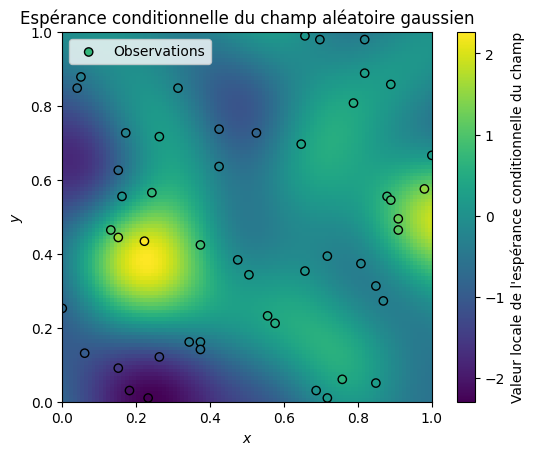

In [41]:
sigma2 = 1.0
a = 0.05

C11 = sigma2 * np.exp(-(mat_dist**2)/a) + 1e-2 * np.identity(50)
C11_inv = np.linalg.inv(C11)
mat_dist_21 = np.array([[np.linalg.norm(coord_tot[i] - pts_obs[j]) for j in range(50)] for i in range(10000)])
C21_tot = sigma2 * np.exp(-(mat_dist_21**2)/a)
# La matrice C21_tot ici implémentée ne correspond pas tout à fait à la matrice C21 définie dans la question 1.
# En effet, déterminer séparément X1 et X2, puis les concaténer, conduit à des discontinuités dans les représentations, notamment liées à l'ajout d'un terme de régularisation non négligeable.
# Nous utilisons donc la matrice C21_tot dans laquelle, en un sens, on substitue X à X2.
# Cette approche n'est pas préjudiciable au résultat final, puisque la seule différence concrète est qu'elle supprime un artefact de représentation en les points d'observation.
esp_cond = np.dot(np.dot(C21_tot, C11_inv), X1)
esp_cond_reshaped_transposed = esp_cond.reshape(n,n).transpose()

plt.imshow(esp_cond_reshaped_transposed, origin="lower", extent=[0,1,0,1])
plt.scatter(pts_obs[:,0], pts_obs[:,1], c=X1, cmap="viridis", edgecolors="k", label="Observations")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.colorbar(label = "Valeur locale de l'espérance conditionnelle du champ")
plt.title("Espérance conditionnelle du champ aléatoire gaussien")
plt.legend()
plt.show()

4. Pour générer de manière indépendante la différence entre l'espérance conditionnelle et le vecteur des points non observés, on génère une seconde réalisation du champ aléatoire aux points de la grille **et** aux coordonnées des points observés par la méthode spectrale. On calcule ensuite la différence entre cette réalisation et l'espérance conditionnelle sachant les valeurs simulées aux coordonnées des points observés. Enfin, on additionne cette différence à l'espérance conditionnelle sachant les observations pour obtenir une réalisation conditionnelle du champ aléatoire Gaussien sur la grille. Implémenter cette approche et représenter une réalisation conditionnelle du champ aléatoire Gaussien sur la grille.

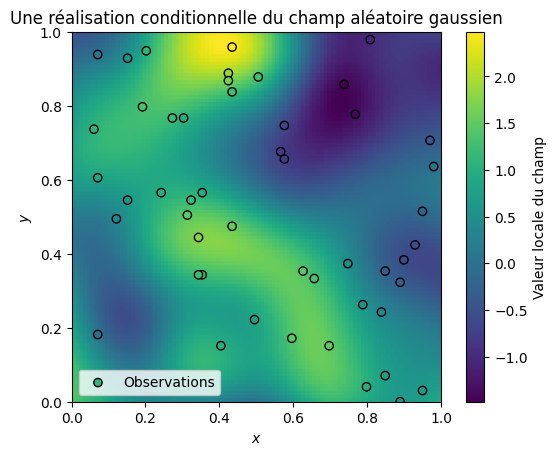

In [ ]:
# 1. Réalisation indépendante du champ
m = len(coord_tot)
N = 10000
W = rng.multivariate_normal([0, 0], (2/a)*np.identity(2), N)
Phi = rng.uniform(0, 2*np.pi, N)
termes = np.cos(np.dot(coord_tot, W.transpose()) + Phi)
champ_sim = np.sqrt(2/N) * np.sum(termes, axis=1)

# 2. Espérance conditionnelle sachant les valeurs simulées
X1_sim = champ_sim[pts_obs_index]
C11 = sigma2 * np.exp(-(mat_dist**2)/a) + 1e-2 * np.identity(50)
C11_inv = np.linalg.inv(C11)
mat_dist_21 = np.array([[np.linalg.norm(coord_tot[i] - pts_obs[j]) for j in range(50)] for i in range(10000)])
C21_tot = sigma2 * np.exp(-(mat_dist_21**2)/a)
esp_cond_sim = np.dot(np.dot(C21_tot, C11_inv), X1_sim)

# 3. Somme finale
somme = champ_sim - esp_cond_sim + esp_cond
somme_reshaped_transposed = somme.reshape(n,n).transpose()

# 4. Affichage
plt.imshow(somme_reshaped_transposed, origin="lower", extent=[0,1,0,1])
plt.scatter(pts_obs[:,0], pts_obs[:,1], c=X1, cmap="viridis", edgecolors="k", label="Observations")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.colorbar(label = "Valeur locale du champ")
plt.title("Une réalisation conditionnelle du champ aléatoire gaussien")
plt.legend()
plt.show()

5. Générer 500 simulations conditionnelles et comparer la moyenne empirique de ces simulations avec l'espérance conditionnelle calculée précédemment. Que constate-t-on ? Expliquer pourquoi.

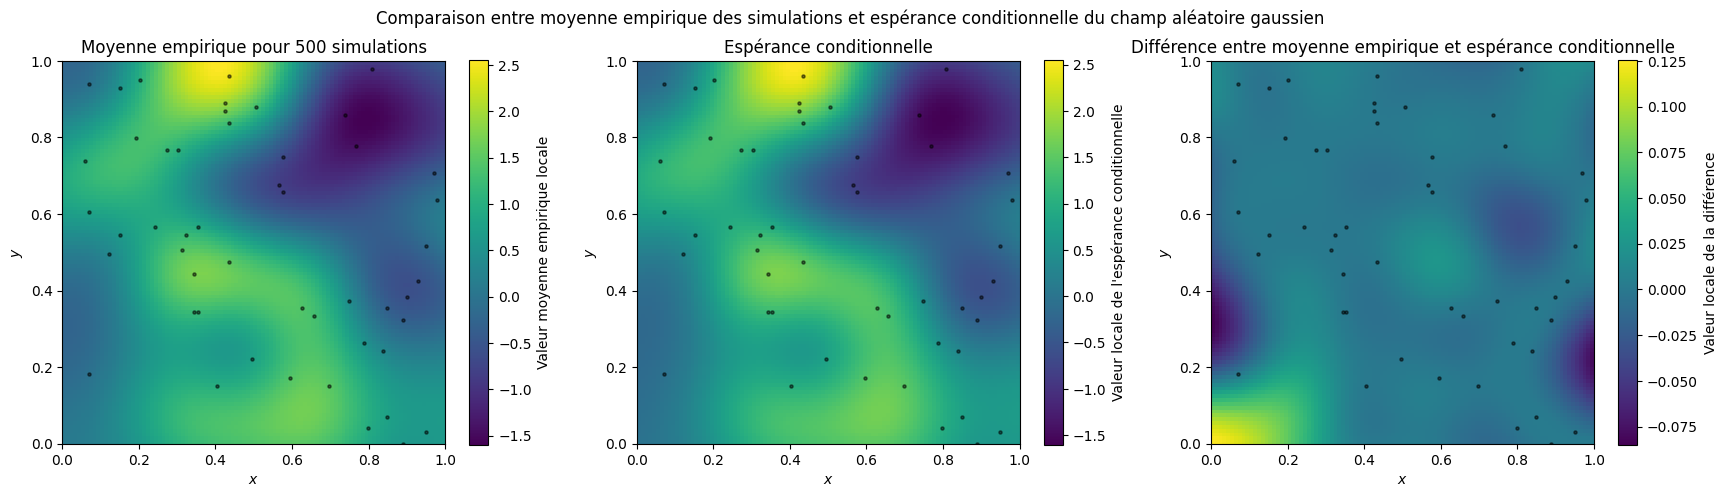

In [ ]:
# Calcul préalable
C11 = sigma2 * np.exp(-(mat_dist**2)/a) + 1e-2 * np.identity(50)
C11_inv = np.linalg.inv(C11)
mat_dist_21 = np.array([[np.linalg.norm(coord_tot[i] - pts_obs[j]) for j in range(50)] for i in range(10000)])
C21_tot = sigma2 * np.exp(-(mat_dist_21**2)/a)
fact = np.dot(C21_tot, C11_inv)

somme_sim = np.zeros_like(somme)

for i in range(500) :

    W = rng.multivariate_normal([0, 0], (2/a)*np.identity(2), N)
    Phi = rng.uniform(0, 2*np.pi, N)
    termes = np.cos(np.dot(coord_tot, W.transpose()) + Phi)
    champ_sim = np.sqrt(2/N) * np.sum(termes, axis=1)

    X1_sim = champ_sim[pts_obs_index]
    esp_cond_sim = np.dot(fact, X1_sim)

    somme_aux = champ_sim - esp_cond_sim + esp_cond
    somme_sim += somme_aux

moy_emp = somme_sim/500
moy_emp_reshaped_transposed = moy_emp.reshape(n,n).transpose()

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(21,5))

im1 = axes[0].imshow(moy_emp_reshaped_transposed, origin="lower", extent=[0,1,0,1])
axes[0].set_title("Moyenne empirique pour 500 simulations")
fig.colorbar(im1, ax=axes[0], label="Valeur moyenne empirique locale")

im2 = axes[1].imshow(esp_cond_reshaped_transposed, origin="lower", extent=[0,1,0,1])
axes[1].set_title("Espérance conditionnelle")
fig.colorbar(im2, ax=axes[1], label="Valeur locale de l'espérance conditionnelle")

diff = moy_emp - esp_cond
diff_reshaped_transposed = diff.reshape(n,n).transpose()
im3 = axes[2].imshow(diff_reshaped_transposed, origin="lower", extent=[0,1,0,1])
axes[2].set_title("Différence entre moyenne empirique et espérance conditionnelle")
fig.colorbar(im3, ax=axes[2], label="Valeur locale de la différence")

for i in range(3) :
    axes[i].scatter(pts_obs[:,0], pts_obs[:,1], color="k", s=5, alpha=0.5)
    axes[i].set_xlabel("$x$")
    axes[i].set_ylabel("$y$")

plt.suptitle("Comparaison entre moyenne empirique des simulations et espérance conditionnelle du champ aléatoire gaussien")

plt.show()

*Remarque* : Par abus de langage, l'expression "espérance conditionnelle de $X_2$ sachant $X_1$" signifie parfois "vecteur aléatoire formé par la concaténation de $X_1$ et de l'espérance conditionnelle de $X_2$ sachant $X_1$" (et renvoie donc au vecteur aléatoire $\mathbb{E}^*(X_2 \,| \,  X_1)$ défini de façon analogue à ce qui suit).

Pour $n \in \mathbb{N}^*$, notons $X^{(n)}$ le vecteur aléatoire gaussien initialement généré pour effectuer la $n^e$ simulation. Notons $\mathbb{E}^*(X^{(n)}_2 \,| \,  X^{(n)}_1) \coloneqq \left(X^{(n)}_1 \quad \mathbb{E}(X^{(n)}_2 \,| \,  X^{(n)}_1)\right)$. Le vecteur correspondant à la simulation conditionnelle est donc
$$X^{(n)}_{cond} \coloneqq X^{(n)} - \mathbb{E}^*(X^{(n)}_2 \,| \,  X^{(n)}_1) + \widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)}$$
où $\widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)} = \left(\widetilde{X_1} \quad \widetilde{\mathbb{E}(X_2 \,| \,  X_1)}\right)$, avec $\widetilde{X_1}$ un vecteur aléatoire déterministe de valeur égale à la réalisation de $X_1$ de la question 2, et $\widetilde{\mathbb{E}(X_2 \,| \,  X_1)}$ un vecteur aléatoire déterministe de valeur égale à la réalisation de l'espérance conditionnelle de la question 3. La suite $\left(X^{(n)}\right)_{n \in \mathbb{N}^*} = \left(\left(X^{(n)}_1 \quad X^{(n)}_2\right)\right)_{n \in \mathbb{N}^*}$ étant une suite de vecteurs aléatoires indépendants et identiquement distribués (i.i.d.), on en déduit que les vecteurs aléatoires de la suite $\left(X^{(n)}_{cond}\right)_{n \in \mathbb{N}^*}$ sont également i.i.d.. Comme les vecteurs aléatoires $X^{(n)}$, $X_1^{(n)}$ et $\mathbb{E}(X^{(n)}_2 \,| \,  X^{(n)}_1)$ suivent des lois normales, et comme $\widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)}$ est déterministe, ils sont intégrables. Donc, comme $\mathbb{E}^*(X^{(n)}_2 \,| \,  X^{(n)}_1) = \left(X^{(n)}_1 \quad \mathbb{E}(X^{(n)}_2 \,| \,  X^{(n)}_1)\right)$, $X^{(n)}_{cond} = X^{(n)} - \mathbb{E}^*(X^{(n)}_2 \,| \,  X^{(n)}_1) + \widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)}$ est intégrable. On note $\mathcal{E} \coloneqq \mathbb{E}(X^{(1)}_{cond}) = \mathbb{E}(X^{(n)}_{cond}) \: (\forall n \in \mathbb{N}^*)$.

Alors, d'après la <u>loi des grands nombres</u>,
$$\displaystyle M_n \coloneqq \frac{\sum_{i=1}^{n} X^{(n)}_{cond}}{n} \xrightarrow[n \to +\infty]{p.s.} \mathcal{E}$$

Or
$$\mathcal{E} = \mathbb{E}(X^{(1)}_{cond}) = \mathbb{E}(X^{(1)}) - \underbrace{\mathbb{E}(\mathbb{E}^*(X^{(1)}_2 \,| \,  X^{(1)}_1))}_{= \left(\mathbb{E}(X^{(1)}_1) \quad \mathbb{E}(X^{(1)}_2)\right) = \mathbb{E}(X^{(1)})} + \underbrace{\mathbb{E}(\widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)})}_{= \widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)}} = \widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)}$$

En résumé,
$$\displaystyle \boxed{M_n \xrightarrow[n \to +\infty]{p.s.} \widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)}}$$
et donc
$$\displaystyle \boxed{M_n \xrightarrow[n \to +\infty]{\mathbb{P}} \widetilde{\mathbb{E}^*(X_2 \,| \,  X_1)}}$$
c'est-à-dire que pour un nombre suffisamment grand de simulations, la moyenne empirique de ces simulations converge presque sûrement et en probabilité vers l'espérance conditionnelle calculée précédemment. C'est exactement ce qu'on observe ci-dessus pour 500 simulations, l'écart normalisé entre moyenne empirique et espérance conditionnelle étant inférieur à 0,05 pour les simulations réalisées.

# Simulation non-stationnaire

On souhaite désormais simuler un champ aléatoire Gaussien non-stationnaire, c'est-à-dire dont la fonction de covariance dépend de la position dans le domaine. Ces modèles plus complexes offrent une plus grande flexibilité pour modéliser des phénomènes naturels. En particulier, on va chercher à faire varier la valeur du paramètre d'échelle $a$ en fonction de la position. On considère une fonction de covariance de la forme :
$$C(x, y) = 2\frac{\sqrt{a(x) a(y)}}{a(x)+a(y)} \exp\left(-\frac{2\|x - y\|^2}{a(x)+a(y)}\right),$$
où $a : [0,1]^2 \to \mathbb{R}_+^*$ est une fonction définissant le paramètre d'échelle en chaque point du domaine.

Pour générer des réalisations de ce champ aléatoire non-stationnaire, on peut adapter la méthode spectrale en utilisant une approche locale. Précisément, on va considérer la modification suivante de la méthode spectrale :

$$Z(x) = \sqrt{\frac{2f_x(W)}{g(W)}}\cos(\langle W, x \rangle + \Phi)$$

où $W$ et $\Phi$ sont deux variables aléatoires indépendantes, de lois respectives $\mathcal{N}(0, \frac{2}{a} I_2)$ et $\mathcal{U}[0, 2\pi[$, et où $f_x$ est la densité de la loi $\mathcal{N}(0, \frac{2}{a(x)} I_2)$ et $g$ est la densité de la loi $\mathcal{N}(0, \frac{2}{a} I_2)$ pour $a = \inf_{x \in [0,1]^2} a(x)>0$, avec $a>0$.

1. Justifier que cette modification permet de simuler un champ aléatoire Gaussien non-stationnaire avec la fonction de covariance donnée précédemment. Quelle technique de simulation vue en cours est-elle utilisée ici ?

Soit $x \in \mathbb{R}^2$. 

On cherche à déterminer $\mathbb{E} \left( Z(x) \right)$. Commençons par déterminer $\mathbb{E} \left( Z(x) \,| \,  W \right)$.

Soit $w \in \mathbb{R}$. $g(w)>0$ car c'est la densité de la loi $\mathcal{N}(0, \frac{2}{a} I_2)$. Alors
$$
\mathbb{E} \left( Z(x) \,| \,  W = w\right) = \mathbb{E} \left(\sqrt{\frac{2f_x(W)}{g(W)}} \, \cos(\langle W, x \rangle + \Phi) \, | \, W = w\right) = \sqrt{\frac{2f_x(w)}{g(w)}} \, \mathbb{E} \left(\cos(\langle w, x \rangle + \Phi) \, | \, W = w\right) = \sqrt{\frac{2f_x(w)}{g(w)}} \, \mathbb{E} \left( \cos(\alpha + \Phi) \right)
$$
où $\alpha \coloneqq \langle w, x \rangle$, car $\Phi$ et $W$ sont indépendantes. Donc :
$$
\mathbb{E} \left( Z(x) \,| \,  W = w\right) 
=
\sqrt{\frac{2f_x(w)}{g(w)}} \,
\int_{0}^{2\pi}
\frac{1}{2\pi}\,
\cos(\alpha + \phi)\,d\phi
=
0
$$

Donc :

$$
\boxed{\mathbb{E} \left( Z(x) \,| \,  W \right) = \tilde{0}}
$$
où $\tilde{0}$ désigne la variable aléatoire nulle sur tout l'univers.


Donc :
$$
\boxed{\mathbb{E} \left( Z(x)\right) = \mathbb{E} \left( \mathbb{E} \left( Z(x) \,| \,  W \right) \right) = \mathbb{E} \left( \tilde{0} \right) = 0}
$$

Montrons que $C$ est la fonction de covariance. Soit $y \in \mathbb{R}^2$.

Alors :
$$
\mathrm{Cov} \left( Z(x), Z(y) \right) = \mathbb{E} \left( \left(Z(x) - \mathbb{E} \left( Z(x) \right) \right) \left( Z(y) - \mathbb{E} \left( Z(y) \right) \right) \right) = \mathbb{E} \left(Z(x) \, Z(y) \right)
$$

Donc :

$$
\mathrm{Cov} \left( Z(x), Z(y) \right) = 2 \, \mathbb{E} \left(\frac{\sqrt{f_x(W) \, f_y(W)}}{g(W)} \, \cos(\underbrace{\langle W, x \rangle}_{\coloneqq U} + \Phi) \, \cos(\underbrace{\langle W, y \rangle}_{\coloneqq V} + \Phi) \right)
$$

Donc :

$$
\boxed{\mathrm{Cov} \left( Z(x), Z(y) \right) = \mathbb{E} \left( \frac{\sqrt{f_x(W) \, f_y(W)}}{g(W)} \, \cos(U - V) \right) + \mathbb{E} \left( \frac{\sqrt{f_x(W) \, f_y(W)}}{g(W)} \, \cos(U + V + 2 \, \Phi) \right)}
$$

La même méthode que que celle utilisée pour prouver la nullité de l'espérance de $Z(x)$ permet de prouver que $\boxed{\mathbb{E} \left(\frac{\sqrt{f_x(W) \, f_y(W)}}{g(W)} \, \cos(U + V + 2 \, \Phi) \right) = 0}$.

Donc :

$$
\mathrm{Cov} \left( Z(x), Z(y) \right) = \mathbb{E} \left( \frac{\sqrt{f_x(W) \, f_y(W)}}{g(W)} \, \cos(\langle W, x - y \rangle) \right) = \int_{\mathbb{R}^2} \frac{\sqrt{f_x(w) \, f_y(w)}}{g(w)} \, \cos(\langle w, x - y \rangle) \, g(w) \, dw
$$

Or,
$$
\forall w \in \mathbb{R}^2, \, f_x(w) = \frac{1}{2\pi \sqrt{\mathrm{det}(\frac{2}{a(x)} I_2)}} \exp\!\left(-\frac{1}{2} w^T \left(\frac{a(x)}{2} I_2 \right) w\right) = \frac{a(x)}{4\pi} \exp\!\left(-\frac{a(x)}{4}\| w \|^2 \right)
$$

Donc :
$$
\boxed{\forall w \in \mathbb{R}^2, \, \sqrt{f_x(w) \, f_y(w)} = \frac{\sqrt{a(x) \, a(y)}}{4\pi} \exp\!\left(-\frac{a(x) + a(y)}{8}\| w \|^2 \right) = \frac{2 \sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, \frac{1}{2\pi \sqrt{\mathrm{det}(\frac{4}{a(x) + a(y)} I_2)}} \exp\!\left(-\frac{1}{2} w^T \left(\frac{a(x) + a(y)}{4} I_2 \right) w\right) = \frac{2 \sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, h_{x,y}(w)}
$$

avec $h_{x,y}$ la densité de $ \Theta \sim \mathcal{N}\left(0, \frac{4}{a(x) + a(y)} I_2\right)$.

Ainsi,
$$
\mathrm{Cov} \left( Z(x), Z(y) \right) = 2\frac{\sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, \int_{\mathbb{R}^2} \, \cos(\langle w, x - y \rangle) \, h_{x,y}(w) \, dw = 2\frac{\sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, \mathbb{E} \left( \cos(\langle \Theta, x - y \rangle) \right) = 2\frac{\sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, \mathrm{Re} \left( \mathbb{E}\left( e^{i \, \langle \Theta, x - y \rangle} \right) \right) = 2\frac{\sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, \mathrm{Re} \left( \Phi_{\Theta}(x - y) \right)
$$

Soit encore :
$$
\boxed{\mathrm{Cov} \left( Z(x), Z(y) \right) = 2\frac{\sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, \mathrm{Re} \left( e^{i \, \langle \underbrace{\mathbb{E} \left( \Theta \right)}_{= 0}, x - y \rangle - \frac{2}{a(x) + a(y)} \; \langle x - y, I_2 \, (x - y) \rangle} \right) = 2\frac{\sqrt{a(x) \, a(y)}}{a(x) + a(y)} \, e^{- \frac{2 \| x - y \|^2}{a(x) + a(y)}} = C(x, y)}
$$

Ainsi, $C$ est bien la fonction de covariance.

Soient les suites de variables aléatoires indépendantes $(W_n)_{n \in \mathbb{N}}$ et $(\Phi_n)_{n \in \mathbb{N}}$ telles que $W_n \sim \mathcal{N}(0, \frac{2}{a} I_2)$ et $\Phi_n \sim \mathcal{U}([0, 2\pi[)$. Alors on montre comme dans la question 3 de la deuxième partie ("Simulation par la méthode spectrale") que pour tout ensemble fini de points  $x_1, \ldots, x_n$ dans  $\mathbb{R}^2$ , le vecteur aléatoire $\boxed{Y = (Y(x_1), \ldots, Y(x_n))}$ où :
$$\boxed{Y(x_i) = \sqrt{\frac{2}{N}} \sum_{k=1}^{N} \sqrt{\frac{f_{x_i}(W_k)}{g(W_k)}} \cos(\langle W_k, x_i \rangle + \Phi_k)}$$
<u>tend vers un vecteur aléatoire de loi normale multivariée d'espérance nulle et de matrice de covariance $K$ définie par $K_{ij} = C(x_i, x_j)$</u>.

On utilise ici la méthode d'**échantillonage d'importance**.

2. Implémenter cette méthode pour simuler un champ aléatoire Gaussien non-stationnaire sur une grille régulière de points dans le domaine  $[0, 1] \times [0, 1]$. On choisira, par exemple, une fonction $a(x)$ variant linéairement selon l'axe des ordonnées entre deux valeurs $a_{min}=0.01$ et $a_{max}=0.1$ sur le domaine. Commenter les résultats obtenus.

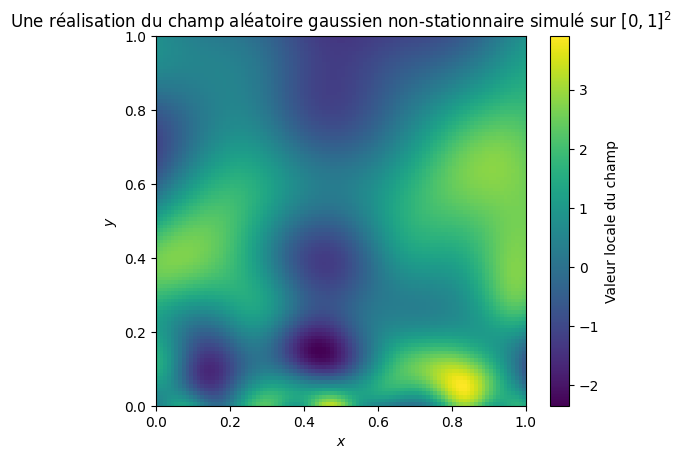

In [15]:
n = 100
m = n**2
N = 10000
coord_tot = coord(n)
a_min = 0.01
a_max = 0.1

a_x = a_min + (a_max - a_min) * coord_tot[:,1]
W = rng.multivariate_normal([0, 0], (2/a_min)*np.identity(2), N)
Phi = rng.uniform(0, 2*np.pi, N)
W_norm2 = np.sum(W**2, axis=1)
rapport = (a_x[:,np.newaxis]/a_min) * np.exp(-(a_x[:,np.newaxis] - a_min) * W_norm2[np.newaxis,:]/4)
termes = np.sqrt(2 *rapport) * np.cos(np.dot(coord_tot, W.transpose()) + Phi)
Y = np.sqrt(2/N) * np.sum(termes, axis=1)
Y_reshaped_transposed = Y.reshape(n,n).transpose()

plt.imshow(Y_reshaped_transposed, origin="lower", extent=[0,1,0,1])
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.colorbar(label = "Valeur locale du champ")
plt.title("Une réalisation du champ aléatoire gaussien non-stationnaire simulé sur $[0, 1]^2$")
plt.show()

- On observe que pour **$y$ proche de $0$**, comme le paramètre $a$ est minimal, **la longueur de corrélation est très courte**, c'est-à-dire que la valeur du champ peut varier fortement d'un point à l'autre : le champ varie rapidement (dans l'espace). La représentation a un **aspect "bruité"** dans ce domaine.

- Au contraire, pour **$y$ proche de $1$**, comme le paramètre $a$ est maximal, **la longueur de corrélation est plus grande**, c'est-à-dire que la cohérence spatiale est plus importante : le champ varie plus lentement (dans l'espace). La représentation présente de **larges surfaces "lisses"**.

Le champ aléatoire gaussien simulé est donc bien non-stationnaire.